In [3]:
# Numerical operations
import numpy as np

# Data manipulation
import pandas as pd

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Machine Learning preprocessing
from sklearn.preprocessing import LabelEncoder, StandardScaler

# Dataset splitting
from sklearn.model_selection import train_test_split

# Machine Learning algorithms
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

# Model evaluation
from sklearn.metrics import accuracy_score
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix
from sklearn.metrics import precision_score
from sklearn.metrics import recall_score
from sklearn.metrics import f1_score

print("All libraries imported successfully!")

All libraries imported successfully!


In [5]:
# Load Bangalore Traffic Dataset

traffic_congestion = pd.read_csv(
    "Banglore_traffic_Dataset.csv"
)

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [6]:
traffic_congestion.head()

,Date,Area Name,Road/Intersection Name,Traffic Volume,Average Speed,Travel Time Index,Congestion Level,Road Capacity Utilization,Incident Reports,Environmental Impact,Public Transport Usage,Traffic Signal Compliance,Parking Usage,Pedestrian and Cyclist Count,Weather Conditions,Roadwork and Construction Activity
0,2022-01-01,Indiranagar,100 Feet Road,50590,50.230299,1.500000,100.000000,100.000000,0,151.180,70.632330,84.044600,85.403629,111,Clear,No
1,2022-01-01,Indiranagar,CMH Road,30825,29.377125,1.500000,100.000000,100.000000,1,111.650,41.924899,91.407038,59.983689,100,Clear,No
2,2022-01-01,Whitefield,Marathahalli Bridge,7399,54.474398,1.039069,28.347994,36.396525,0,64.798,44.662384,61.375541,95.466020,189,Clear,No
3,2022-01-01,Koramangala,Sony World Junction,60874,43.817610,1.500000,100.000000,100.000000,1,171.748,32.773123,75.547092,63.567452,111,Clear,No
4,2022-01-01,Koramangala,Sarjapur Road,57292,41.116763,1.500000,100.000000,100.000000,3,164.584,35.092601,64.634762,93.155171,104,Clear,No


In [7]:
traffic_congestion.tail()

,Date,Area Name,Road/Intersection Name,Traffic Volume,Average Speed,Travel Time Index,Congestion Level,Road Capacity Utilization,Incident Reports,Environmental Impact,Public Transport Usage,Traffic Signal Compliance,Parking Usage,Pedestrian and Cyclist Count,Weather Conditions,Roadwork and Construction Activity
8931,2024-08-09,Electronic City,Hosur Road,11387,23.440276,1.262384,35.871483,57.354487,1,72.774,21.523289,83.530352,97.898279,211,Fog,No
8932,2024-08-09,M.G. Road,Trinity Circle,36477,45.168429,1.500000,100.000000,100.000000,3,122.954,29.822312,60.738488,60.355967,95,Clear,No
8933,2024-08-09,M.G. Road,Anil Kumble Circle,42822,22.028609,1.500000,100.000000,100.000000,1,135.644,43.185905,85.321627,61.333731,110,Clear,No
8934,2024-08-09,Jayanagar,South End Circle,20540,52.254798,1.020520,72.639152,97.845527,2,91.080,44.416043,89.586947,79.197198,94,Clear,No
8935,2024-08-09,Yeshwanthpur,Yeshwanthpur Circle,14705,31.128967,1.048720,43.409821,77.734621,1,79.410,26.616725,80.778753,60.602672,201,Rain,No


In [8]:
print("Total Rows:", traffic_congestion.shape[0])

print("Total Columns:", traffic_congestion.shape[1])

print("Dataset Shape:", traffic_congestion.shape)

Total Rows: 8936
Total Columns: 16
Dataset Shape: (8936, 16)


In [9]:
traffic_congestion.info()

<class 'pandas.DataFrame'>
RangeIndex: 8936 entries, 0 to 8935
Data columns (total 16 columns):
 #   Column                              Non-Null Count  Dtype  
---  ------                              --------------  -----  
 0   Date                                8936 non-null   str    
 1   Area Name                           8936 non-null   str    
 2   Road/Intersection Name              8936 non-null   str    
 3   Traffic Volume                      8936 non-null   int64  
 4   Average Speed                       8936 non-null   float64
 5   Travel Time Index                   8936 non-null   float64
 6   Congestion Level                    8936 non-null   float64
 7   Road Capacity Utilization           8936 non-null   float64
 8   Incident Reports                    8936 non-null   int64  
 9   Environmental Impact                8936 non-null   float64
 10  Public Transport Usage              8936 non-null   float64
 11  Traffic Signal Compliance           8936 non-null   fl

In [10]:
traffic_congestion.columns

Index(['Date', 'Area Name', 'Road/Intersection Name', 'Traffic Volume',
       'Average Speed', 'Travel Time Index', 'Congestion Level',
       'Road Capacity Utilization', 'Incident Reports', 'Environmental Impact',
       'Public Transport Usage', 'Traffic Signal Compliance', 'Parking Usage',
       'Pedestrian and Cyclist Count', 'Weather Conditions',
       'Roadwork and Construction Activity'],
      dtype='str')

In [11]:
traffic_congestion.dtypes

Date                                      str
Area Name                                 str
Road/Intersection Name                    str
Traffic Volume                          int64
Average Speed                         float64
Travel Time Index                     float64
Congestion Level                      float64
Road Capacity Utilization             float64
Incident Reports                        int64
Environmental Impact                  float64
Public Transport Usage                float64
Traffic Signal Compliance             float64
Parking Usage                         float64
Pedestrian and Cyclist Count            int64
Weather Conditions                        str
Roadwork and Construction Activity        str
dtype: object

In [12]:
traffic_congestion.describe()

,Traffic Volume,Average Speed,Travel Time Index,Congestion Level,Road Capacity Utilization,Incident Reports,Environmental Impact,Public Transport Usage,Traffic Signal Compliance,Parking Usage,Pedestrian and Cyclist Count
count,8936.000000,8936.000000,8936.000000,8936.000000,8936.000000,8936.000000,8936.000000,8936.000000,8936.000000,8936.000000,8936.000000
mean,29236.048120,39.447427,1.375554,80.818041,92.029215,1.570389,108.472096,45.086651,79.950243,75.155597,114.533348
std,13001.808801,10.707244,0.165319,23.533182,16.583341,1.420047,26.003618,20.208460,11.585006,14.409394,36.812573
min,4233.000000,20.000000,1.000039,5.160279,18.739771,0.000000,58.466000,10.006853,60.003933,50.020411,66.000000
25%,19413.000000,31.775825,1.242459,64.292905,97.354990,0.000000,88.826000,27.341191,69.828270,62.545895,94.000000
50%,27600.000000,39.199368,1.500000,92.389018,100.000000,1.000000,105.200000,45.170684,79.992773,75.317610,102.000000
75%,38058.500000,46.644517,1.500000,100.000000,100.000000,2.000000,126.117000,62.426485,89.957358,87.518589,111.000000
max,72039.000000,89.790843,1.500000,100.000000,100.000000,10.000000,194.078000,79.979744,99.993652,99.995049,243.000000


In [13]:
traffic_congestion.describe(include='all')

,Date,Area Name,Road/Intersection Name,Traffic Volume,Average Speed,Travel Time Index,Congestion Level,Road Capacity Utilization,Incident Reports,Environmental Impact,Public Transport Usage,Traffic Signal Compliance,Parking Usage,Pedestrian and Cyclist Count,Weather Conditions,Roadwork and Construction Activity
count,8936,8936,8936,8936.000000,8936.000000,8936.000000,8936.000000,8936.000000,8936.000000,8936.000000,8936.000000,8936.000000,8936.000000,8936.000000,8936,8936
unique,952,8,16,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5,2
top,2023-01-24,Indiranagar,100 Feet Road,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Clear,No
freq,15,1720,860,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5426,8054
mean,NaN,NaN,NaN,29236.048120,39.447427,1.375554,80.818041,92.029215,1.570389,108.472096,45.086651,79.950243,75.155597,114.533348,NaN,NaN
std,NaN,NaN,NaN,13001.808801,10.707244,0.165319,23.533182,16.583341,1.420047,26.003618,20.208460,11.585006,14.409394,36.812573,NaN,NaN
min,NaN,NaN,NaN,4233.000000,20.000000,1.000039,5.160279,18.739771,0.000000,58.466000,10.006853,60.003933,50.020411,66.000000,NaN,NaN
25%,NaN,NaN,NaN,19413.000000,31.775825,1.242459,64.292905,97.354990,0.000000,88.826000,27.341191,69.828270,62.545895,94.000000,NaN,NaN
50%,NaN,NaN,NaN,27600.000000,39.199368,1.500000,92.389018,100.000000,1.000000,105.200000,45.170684,79.992773,75.317610,102.000000,NaN,NaN
75%,NaN,NaN,NaN,38058.500000,46.644517,1.500000,100.000000,100.000000,2.000000,126.117000,62.426485,89.957358,87.518589,111.000000,NaN,NaN


In [14]:
#for checking unique value
for column in traffic_congestion.columns:

    print("\nColumn:", column)

    print("Unique Values:", traffic_congestion[column].nunique())


Column: Date
Unique Values: 952

Column: Area Name
Unique Values: 8

Column: Road/Intersection Name
Unique Values: 16

Column: Traffic Volume
Unique Values: 8100

Column: Average Speed
Unique Values: 8572

Column: Travel Time Index
Unique Values: 3711

Column: Congestion Level
Unique Values: 5053

Column: Road Capacity Utilization
Unique Values: 2352

Column: Incident Reports
Unique Values: 11

Column: Environmental Impact
Unique Values: 8100

Column: Public Transport Usage
Unique Values: 8936

Column: Traffic Signal Compliance
Unique Values: 8936

Column: Parking Usage
Unique Values: 8936

Column: Pedestrian and Cyclist Count
Unique Values: 148

Column: Weather Conditions
Unique Values: 5

Column: Roadwork and Construction Activity
Unique Values: 2


In [15]:
for column in traffic_congestion.columns:

    print("\nColumn:", column)

    print("Unique Values:", traffic_congestion[column].nunique())


Column: Date
Unique Values: 952

Column: Area Name
Unique Values: 8

Column: Road/Intersection Name
Unique Values: 16

Column: Traffic Volume
Unique Values: 8100

Column: Average Speed
Unique Values: 8572

Column: Travel Time Index
Unique Values: 3711

Column: Congestion Level
Unique Values: 5053

Column: Road Capacity Utilization
Unique Values: 2352

Column: Incident Reports
Unique Values: 11

Column: Environmental Impact
Unique Values: 8100

Column: Public Transport Usage
Unique Values: 8936

Column: Traffic Signal Compliance
Unique Values: 8936

Column: Parking Usage
Unique Values: 8936

Column: Pedestrian and Cyclist Count
Unique Values: 148

Column: Weather Conditions
Unique Values: 5

Column: Roadwork and Construction Activity
Unique Values: 2


In [16]:
print("Missing Values in Each Column:")

print(traffic_congestion.isnull().sum())

print("\nTotal Missing Values:",
      traffic_congestion.isnull().sum().sum())

Missing Values in Each Column:
Date                                  0
Area Name                             0
Road/Intersection Name                0
Traffic Volume                        0
Average Speed                         0
Travel Time Index                     0
Congestion Level                      0
Road Capacity Utilization             0
Incident Reports                      0
Environmental Impact                  0
Public Transport Usage                0
Traffic Signal Compliance             0
Parking Usage                         0
Pedestrian and Cyclist Count          0
Weather Conditions                    0
Roadwork and Construction Activity    0
dtype: int64

Total Missing Values: 0


In [17]:
traffic_congestion.isnull().sum()

Date                                  0
Area Name                             0
Road/Intersection Name                0
Traffic Volume                        0
Average Speed                         0
Travel Time Index                     0
Congestion Level                      0
Road Capacity Utilization             0
Incident Reports                      0
Environmental Impact                  0
Public Transport Usage                0
Traffic Signal Compliance             0
Parking Usage                         0
Pedestrian and Cyclist Count          0
Weather Conditions                    0
Roadwork and Construction Activity    0
dtype: int64

In [18]:
missing_percentage = (
    traffic_congestion.isnull().sum()
    / len(traffic_congestion)
) * 100

print(missing_percentage)

Date                                  0.0
Area Name                             0.0
Road/Intersection Name                0.0
Traffic Volume                        0.0
Average Speed                         0.0
Travel Time Index                     0.0
Congestion Level                      0.0
Road Capacity Utilization             0.0
Incident Reports                      0.0
Environmental Impact                  0.0
Public Transport Usage                0.0
Traffic Signal Compliance             0.0
Parking Usage                         0.0
Pedestrian and Cyclist Count          0.0
Weather Conditions                    0.0
Roadwork and Construction Activity    0.0
dtype: float64


In [19]:
print("Duplicate Records:",
      traffic_congestion.duplicated().sum())

Duplicate Records: 0


In [20]:
print("Duplicate Records:",
      traffic_congestion.duplicated().sum())

Duplicate Records: 0


In [21]:
print(traffic_congestion['Date'].head())

print("\nDate Data Type:",
      traffic_congestion['Date'].dtype)

0    2022-01-01
1    2022-01-01
2    2022-01-01
3    2022-01-01
4    2022-01-01
Name: Date, dtype: str

Date Data Type: str


In [22]:
traffic_congestion['Date'] = pd.to_datetime(
    traffic_congestion['Date'],
    errors='coerce'
)

print("Date conversion completed!")

print(traffic_congestion['Date'].dtype)

Date conversion completed!
datetime64[us]


In [23]:
print("Dataset Shape:",
      traffic_congestion.shape)

print("\nMissing Values:")
print(traffic_congestion.isnull().sum())

print("\nDuplicate Records:",
      traffic_congestion.duplicated().sum())

Dataset Shape: (8936, 16)

Missing Values:
Date                                  0
Area Name                             0
Road/Intersection Name                0
Traffic Volume                        0
Average Speed                         0
Travel Time Index                     0
Congestion Level                      0
Road Capacity Utilization             0
Incident Reports                      0
Environmental Impact                  0
Public Transport Usage                0
Traffic Signal Compliance             0
Parking Usage                         0
Pedestrian and Cyclist Count          0
Weather Conditions                    0
Roadwork and Construction Activity    0
dtype: int64

Duplicate Records: 0


In [24]:
# Select numerical columns

numerical_columns = traffic_congestion.select_dtypes(
    include=np.number
).columns

print("Numerical Features:")
print(numerical_columns.tolist())

# Statistical summary

traffic_congestion[numerical_columns].describe()

Numerical Features:
['Traffic Volume', 'Average Speed', 'Travel Time Index', 'Congestion Level', 'Road Capacity Utilization', 'Incident Reports', 'Environmental Impact', 'Public Transport Usage', 'Traffic Signal Compliance', 'Parking Usage', 'Pedestrian and Cyclist Count']


,Traffic Volume,Average Speed,Travel Time Index,Congestion Level,Road Capacity Utilization,Incident Reports,Environmental Impact,Public Transport Usage,Traffic Signal Compliance,Parking Usage,Pedestrian and Cyclist Count
count,8936.000000,8936.000000,8936.000000,8936.000000,8936.000000,8936.000000,8936.000000,8936.000000,8936.000000,8936.000000,8936.000000
mean,29236.048120,39.447427,1.375554,80.818041,92.029215,1.570389,108.472096,45.086651,79.950243,75.155597,114.533348
std,13001.808801,10.707244,0.165319,23.533182,16.583341,1.420047,26.003618,20.208460,11.585006,14.409394,36.812573
min,4233.000000,20.000000,1.000039,5.160279,18.739771,0.000000,58.466000,10.006853,60.003933,50.020411,66.000000
25%,19413.000000,31.775825,1.242459,64.292905,97.354990,0.000000,88.826000,27.341191,69.828270,62.545895,94.000000
50%,27600.000000,39.199368,1.500000,92.389018,100.000000,1.000000,105.200000,45.170684,79.992773,75.317610,102.000000
75%,38058.500000,46.644517,1.500000,100.000000,100.000000,2.000000,126.117000,62.426485,89.957358,87.518589,111.000000
max,72039.000000,89.790843,1.500000,100.000000,100.000000,10.000000,194.078000,79.979744,99.993652,99.995049,243.000000


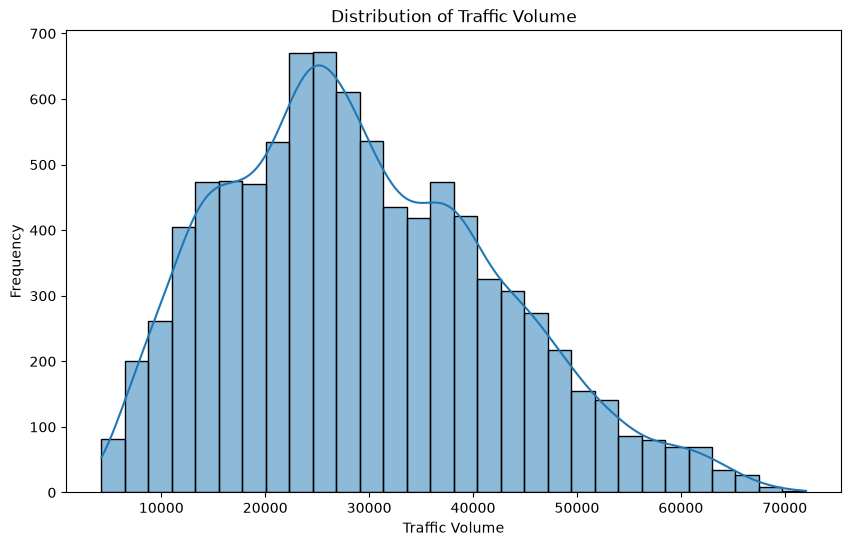

In [25]:
plt.figure(figsize=(10, 6))

sns.histplot(
    traffic_congestion['Traffic Volume'],
    bins=30,
    kde=True
)

plt.title('Distribution of Traffic Volume')

plt.xlabel('Traffic Volume')

plt.ylabel('Frequency')

plt.show()

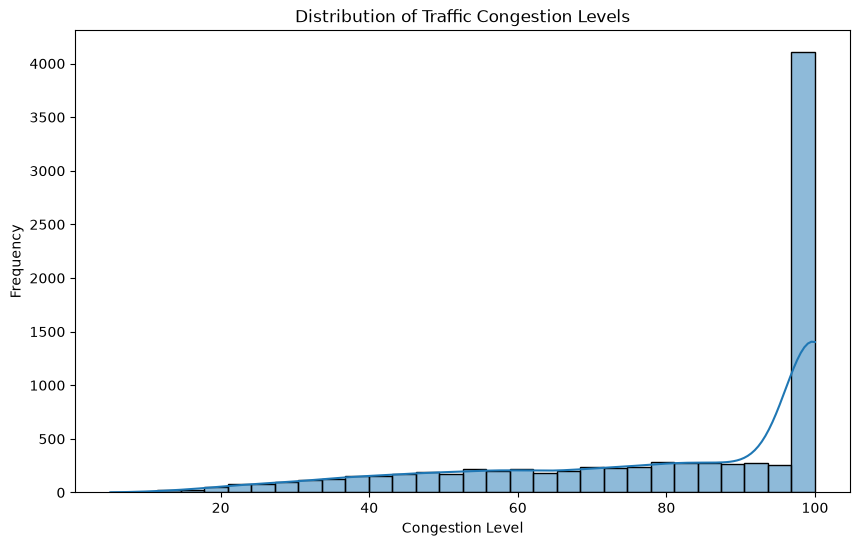

In [26]:
plt.figure(figsize=(10, 6))

sns.histplot(
    traffic_congestion['Congestion Level'],
    bins=30,
    kde=True
)

plt.title('Distribution of Traffic Congestion Levels')

plt.xlabel('Congestion Level')

plt.ylabel('Frequency')

plt.show()

Area-Wise Average Congestion:


Area Name
Koramangala        93.985536
M.G. Road          90.579670
Indiranagar        87.641890
Hebbal             80.087244
Jayanagar          76.998324
Whitefield         69.054661
Yeshwanthpur       62.369634
Electronic City    54.454507
Name: Congestion Level, dtype: float64

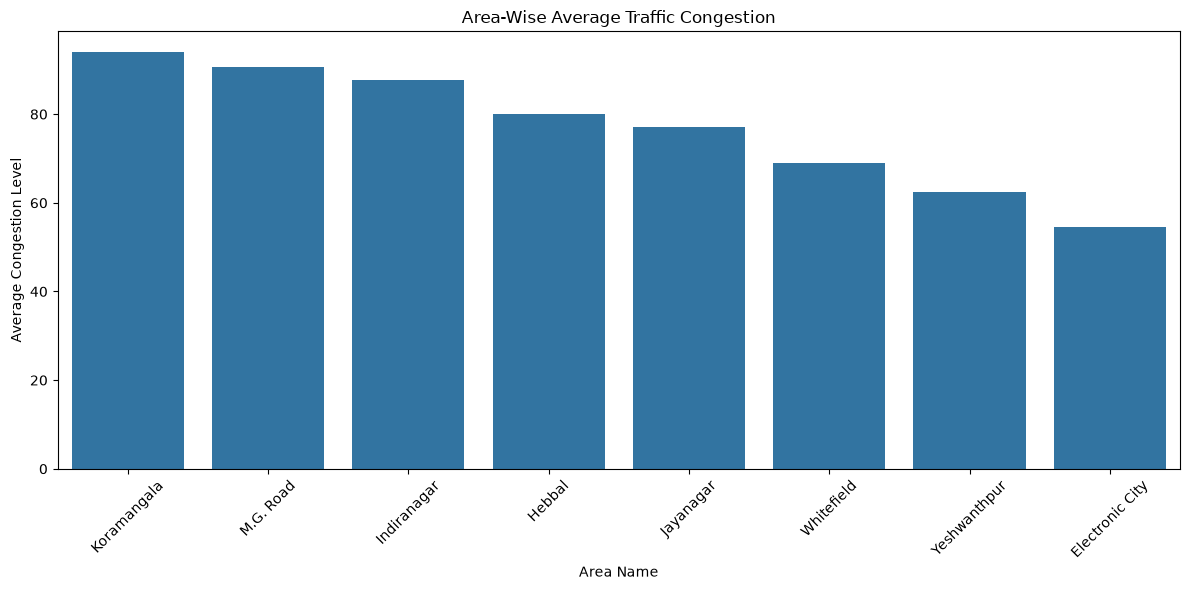

In [27]:
# Calculate average congestion by area

area_congestion = (
    traffic_congestion.groupby('Area Name')['Congestion Level']
    .mean()
    .sort_values(ascending=False)
)

print("Area-Wise Average Congestion:")
display(area_congestion)

# Visualization

plt.figure(figsize=(12, 6))

sns.barplot(
    x=area_congestion.index,
    y=area_congestion.values
)

plt.title('Area-Wise Average Traffic Congestion')

plt.xlabel('Area Name')

plt.ylabel('Average Congestion Level')

plt.xticks(rotation=45)

plt.tight_layout()

plt.show()

Road-Wise Average Congestion:


Road/Intersection Name
Sony World Junction    94.125087
Sarjapur Road          93.845163
Anil Kumble Circle     90.782145
Trinity Circle         90.372556
CMH Road               88.176365
100 Feet Road          87.107415
Hebbal Flyover         80.662354
Ballari Road           79.514551
South End Circle       77.277398
Jayanagar 4th Block    76.712995
ITPL Main Road         71.101106
Marathahalli Bridge    67.182913
Yeshwanthpur Circle    63.744162
Tumkur Road            60.949415
Hosur Road             55.203745
Silk Board Junction    53.699820
Name: Congestion Level, dtype: float64

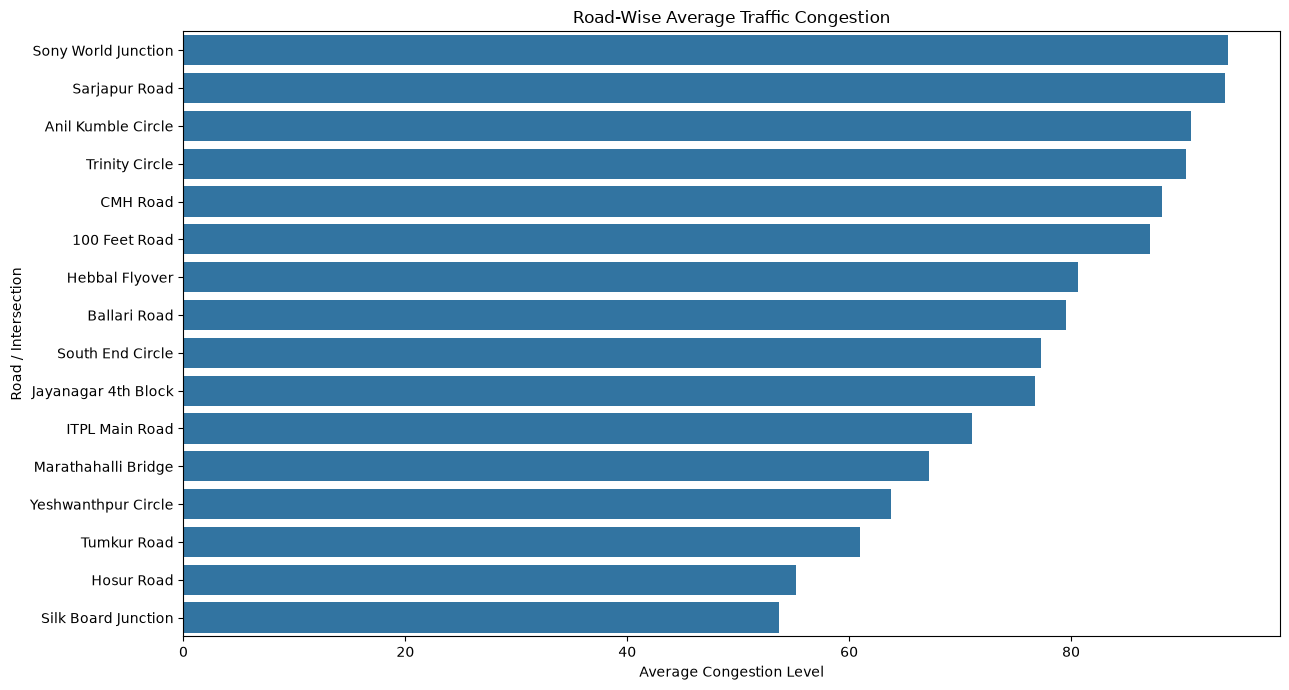

In [28]:
#road wise congestion analysis
# Calculate average congestion for each road

road_congestion = (
    traffic_congestion.groupby('Road/Intersection Name')
    ['Congestion Level']
    .mean()
    .sort_values(ascending=False)
)

print("Road-Wise Average Congestion:")

display(road_congestion)

# Visualization

plt.figure(figsize=(13, 7))

sns.barplot(
    x=road_congestion.values,
    y=road_congestion.index
)

plt.title('Road-Wise Average Traffic Congestion')

plt.xlabel('Average Congestion Level')

plt.ylabel('Road / Intersection')

plt.tight_layout()

plt.show()

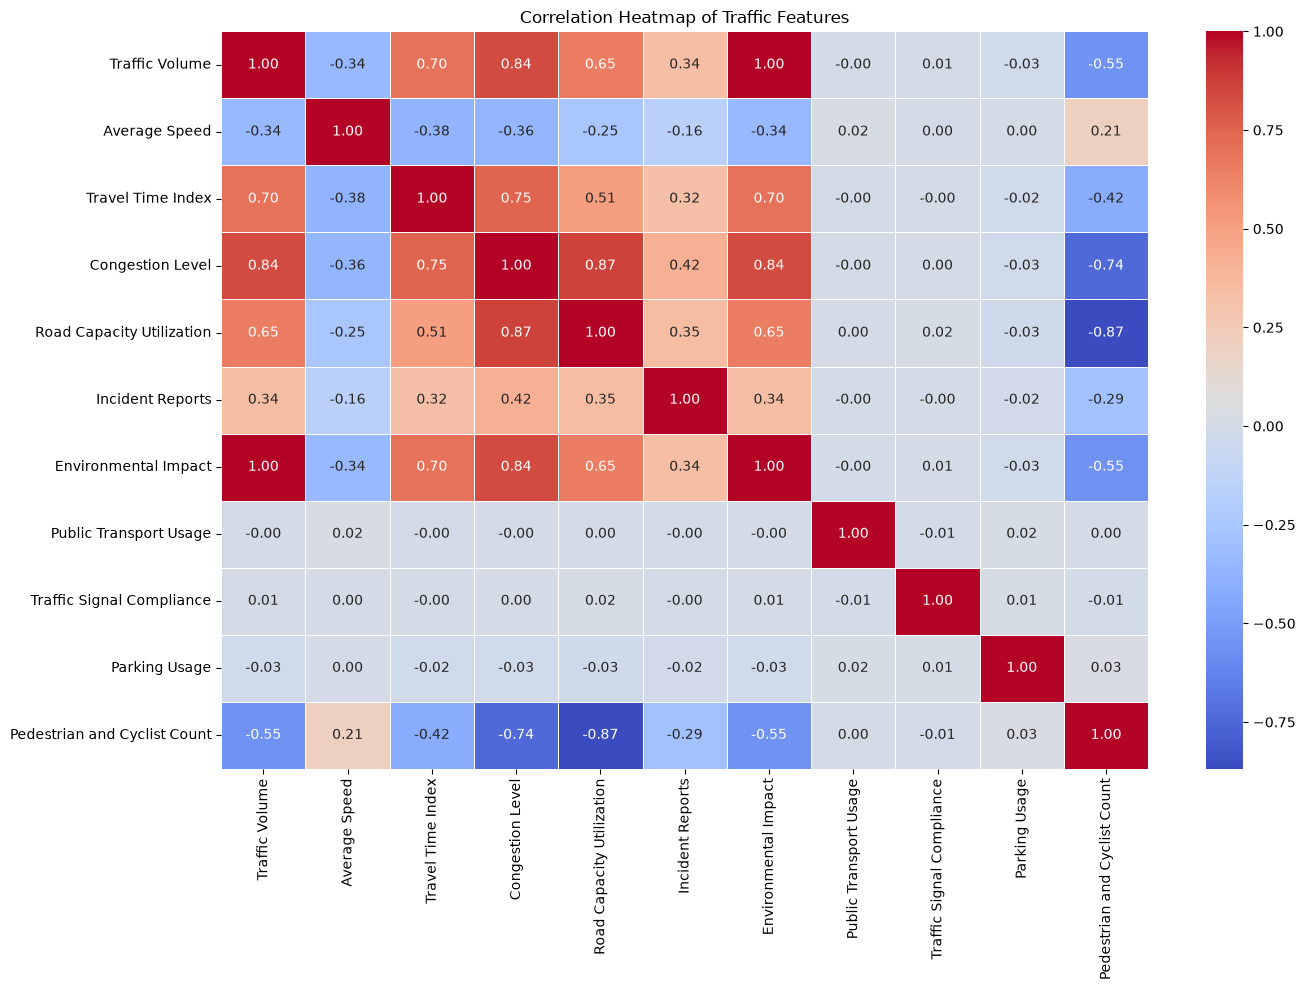

In [29]:
#correlation heatmap
# Calculate correlation matrix

correlation_matrix = traffic_congestion[
    numerical_columns
].corr()

# Create heatmap

plt.figure(figsize=(14, 10))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title('Correlation Heatmap of Traffic Features')

plt.tight_layout()

plt.show()

In [36]:
#save
plt.savefig(
    'Downloads/Result/traffic_volume_distribution.png',
    dpi=300,
    bbox_inches='tight'
)

<Figure size 640x480 with 0 Axes>

In [37]:
#feature scaling

# Create a copy of the cleaned dataset

traffic_congestion = traffic_congestion.copy()

# Display dataset information

print("Dataset copied successfully!")

print("Rows:", traffic_congestion.shape[0])

print("Columns:", traffic_congestion.shape[1])

display(traffic_congestion.head())

Dataset copied successfully!
Rows: 8936
Columns: 16


,Date,Area Name,Road/Intersection Name,Traffic Volume,Average Speed,Travel Time Index,Congestion Level,Road Capacity Utilization,Incident Reports,Environmental Impact,Public Transport Usage,Traffic Signal Compliance,Parking Usage,Pedestrian and Cyclist Count,Weather Conditions,Roadwork and Construction Activity
0,2022-01-01,Indiranagar,100 Feet Road,50590,50.230299,1.500000,100.000000,100.000000,0,151.180,70.632330,84.044600,85.403629,111,Clear,No
1,2022-01-01,Indiranagar,CMH Road,30825,29.377125,1.500000,100.000000,100.000000,1,111.650,41.924899,91.407038,59.983689,100,Clear,No
2,2022-01-01,Whitefield,Marathahalli Bridge,7399,54.474398,1.039069,28.347994,36.396525,0,64.798,44.662384,61.375541,95.466020,189,Clear,No
3,2022-01-01,Koramangala,Sony World Junction,60874,43.817610,1.500000,100.000000,100.000000,1,171.748,32.773123,75.547092,63.567452,111,Clear,No
4,2022-01-01,Koramangala,Sarjapur Road,57292,41.116763,1.500000,100.000000,100.000000,3,164.584,35.092601,64.634762,93.155171,104,Clear,No


In [38]:
# Convert Date column into datetime format

traffic_congestion['Date'] = pd.to_datetime(
    traffic_congestion['Date'],
    errors='coerce'
)

# Check date datatype

print("Date datatype:",
      traffic_congestion['Date'].dtype)

# Check invalid dates

print("Invalid dates:",
      traffic_congestion['Date'].isnull().sum())

# Display date values

display(traffic_congestion[['Date']].head())

Date datatype: datetime64[us]
Invalid dates: 0


,Date
0,2022-01-01
1,2022-01-01
2,2022-01-01
3,2022-01-01
4,2022-01-01


In [39]:
# Extract year

traffic_congestion['Year'] = (
    traffic_congestion['Date'].dt.year
)

# Extract month

traffic_congestion['Month'] = (
    traffic_congestion['Date'].dt.month
)

# Extract day

traffic_congestion['Day'] = (
    traffic_congestion['Date'].dt.day
)

# Display new features

display(
    traffic_congestion[
        ['Date', 'Year', 'Month', 'Day']
    ].head(10)
)

,Date,Year,Month,Day
0,2022-01-01,2022,1,1
1,2022-01-01,2022,1,1
2,2022-01-01,2022,1,1
3,2022-01-01,2022,1,1
4,2022-01-01,2022,1,1
5,2022-01-01,2022,1,1
6,2022-01-01,2022,1,1
7,2022-01-01,2022,1,1
8,2022-01-01,2022,1,1
9,2022-01-01,2022,1,1


In [40]:
#extract day of week and weekend
# Extract day number
# Monday = 0 and Sunday = 6

traffic_congestion['Day_of_Week'] = (
    traffic_congestion['Date'].dt.dayofweek
)

# Extract day name

traffic_congestion['Day_Name'] = (
    traffic_congestion['Date'].dt.day_name()
)

# Identify weekends

traffic_congestion['Is_Weekend'] = (
    traffic_congestion['Day_of_Week'] >= 5
).astype(int)

# Display results

display(
    traffic_congestion[
        ['Date', 'Day_Name', 'Day_of_Week', 'Is_Weekend']
    ].head(10)
)

,Date,Day_Name,Day_of_Week,Is_Weekend
0,2022-01-01,Saturday,5,1
1,2022-01-01,Saturday,5,1
2,2022-01-01,Saturday,5,1
3,2022-01-01,Saturday,5,1
4,2022-01-01,Saturday,5,1
5,2022-01-01,Saturday,5,1
6,2022-01-01,Saturday,5,1
7,2022-01-01,Saturday,5,1
8,2022-01-01,Saturday,5,1
9,2022-01-01,Saturday,5,1


In [41]:
#create season feature
# Define season mapping

def get_season(month):

    if month in [12, 1, 2]:
        return 'Winter'

    elif month in [3, 4, 5]:
        return 'Summer'

    elif month in [6, 7, 8, 9]:
        return 'Monsoon'

    else:
        return 'Post-Monsoon'


# Create Season column

traffic_congestion['Season'] = (
    traffic_congestion['Month'].apply(get_season)
)

# Display seasonal information

display(
    traffic_congestion[
        ['Date', 'Month', 'Season']
    ].head(15)
)

,Date,Month,Season
0,2022-01-01,1,Winter
1,2022-01-01,1,Winter
2,2022-01-01,1,Winter
3,2022-01-01,1,Winter
4,2022-01-01,1,Winter
5,2022-01-01,1,Winter
6,2022-01-01,1,Winter
7,2022-01-01,1,Winter
8,2022-01-01,1,Winter
9,2022-01-01,1,Winter


In [42]:
# Convert roadwork activity into binary values

traffic_congestion['Roadwork_Binary'] = (
    traffic_congestion[
        'Roadwork and Construction Activity'
    ]
    .map({
        'Yes': 1,
        'No': 0
    })
)

# Display results

display(
    traffic_congestion[
        [
            'Roadwork and Construction Activity',
            'Roadwork_Binary'
        ]
    ].head(10)
)

print("\nRoadwork Binary Conversion Completed!")

,Roadwork and Construction Activity,Roadwork_Binary
0,No,0
1,No,0
2,No,0
3,No,0
4,No,0
5,No,0
6,No,0
7,No,0
8,No,0
9,No,0



Roadwork Binary Conversion Completed!


In [45]:
# Display all columns

print("Updated Dataset Columns:")

print(traffic_congestion.columns.tolist())

# Display updated dataset

print("\nUpdated Dataset:")

display(traffic_congestion.head())

# Save engineered dataset

traffic_congestion.to_csv(
    'Downloads/Result/traffic_feature_engineered.csv',
    index=False
)

print("\nFeature engineered dataset saved successfully!")

Updated Dataset Columns:
['Date', 'Area Name', 'Road/Intersection Name', 'Traffic Volume', 'Average Speed', 'Travel Time Index', 'Congestion Level', 'Road Capacity Utilization', 'Incident Reports', 'Environmental Impact', 'Public Transport Usage', 'Traffic Signal Compliance', 'Parking Usage', 'Pedestrian and Cyclist Count', 'Weather Conditions', 'Roadwork and Construction Activity', 'Year', 'Month', 'Day', 'Day_of_Week', 'Day_Name', 'Is_Weekend', 'Season', 'Roadwork_Binary']

Updated Dataset:


,Date,Area Name,Road/Intersection Name,Traffic Volume,Average Speed,Travel Time Index,Congestion Level,Road Capacity Utilization,Incident Reports,Environmental Impact,...,Weather Conditions,Roadwork and Construction Activity,Year,Month,Day,Day_of_Week,Day_Name,Is_Weekend,Season,Roadwork_Binary
0,2022-01-01,Indiranagar,100 Feet Road,50590,50.230299,1.500000,100.000000,100.000000,0,151.180,...,Clear,No,2022,1,1,5,Saturday,1,Winter,0
1,2022-01-01,Indiranagar,CMH Road,30825,29.377125,1.500000,100.000000,100.000000,1,111.650,...,Clear,No,2022,1,1,5,Saturday,1,Winter,0
2,2022-01-01,Whitefield,Marathahalli Bridge,7399,54.474398,1.039069,28.347994,36.396525,0,64.798,...,Clear,No,2022,1,1,5,Saturday,1,Winter,0
3,2022-01-01,Koramangala,Sony World Junction,60874,43.817610,1.500000,100.000000,100.000000,1,171.748,...,Clear,No,2022,1,1,5,Saturday,1,Winter,0
4,2022-01-01,Koramangala,Sarjapur Road,57292,41.116763,1.500000,100.000000,100.000000,3,164.584,...,Clear,No,2022,1,1,5,Saturday,1,Winter,0



Feature engineered dataset saved successfully!


In [46]:
#import preprocessing library
# Import preprocessing libraries

from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import OneHotEncoder

from sklearn.model_selection import train_test_split

from sklearn.compose import ColumnTransformer

from sklearn.pipeline import Pipeline

from sklearn.impute import SimpleImputer

print("Preprocessing libraries imported successfully!")

Preprocessing libraries imported successfully!


In [47]:
# Convert Date into datetime format

traffic_congestion['Date'] = pd.to_datetime(
    traffic_congestion['Date'],
    errors='coerce'
)

# Extract year, month and day

traffic_congestion['Year'] = (
    traffic_congestion['Date'].dt.year
)

traffic_congestion['Month'] = (
    traffic_congestion['Date'].dt.month
)

traffic_congestion['Day'] = (
    traffic_congestion['Date'].dt.day
)

# Extract day of week

traffic_congestion['Day_of_Week'] = (
    traffic_congestion['Date'].dt.dayofweek
)

# Identify weekends

traffic_congestion['Is_Weekend'] = (
    traffic_congestion['Day_of_Week'] >= 5
).astype(int)

# Create season feature

def get_season(month):

    if month in [12, 1, 2]:
        return 'Winter'

    elif month in [3, 4, 5]:
        return 'Summer'

    elif month in [6, 7, 8, 9]:
        return 'Monsoon'

    else:
        return 'Post-Monsoon'

traffic_congestion['Season'] = (
    traffic_congestion['Month'].apply(get_season)
)

print("Date features prepared successfully!")

display(
    traffic_congestion[
        ['Date', 'Year', 'Month', 'Day',
         'Day_of_Week', 'Is_Weekend', 'Season']
    ].head()
)

Date features prepared successfully!


,Date,Year,Month,Day,Day_of_Week,Is_Weekend,Season
0,2022-01-01,2022,1,1,5,1,Winter
1,2022-01-01,2022,1,1,5,1,Winter
2,2022-01-01,2022,1,1,5,1,Winter
3,2022-01-01,2022,1,1,5,1,Winter
4,2022-01-01,2022,1,1,5,1,Winter


In [48]:
#create target variable
# Define congestion categories

traffic_congestion['Congestion_Class'] = pd.cut(
    traffic_congestion['Congestion Level'],
    bins=[0, 40, 70, 100],
    labels=['Low', 'Medium', 'High'],
    include_lowest=True
)

# Display target variable

display(
    traffic_congestion[
        ['Congestion Level', 'Congestion_Class']
    ].head(10)
)

# Check class distribution

print("\nCongestion Class Distribution:")

print(
    traffic_congestion['Congestion_Class'].value_counts()
)

,Congestion Level,Congestion_Class
0,100.000000,High
1,100.000000,High
2,28.347994,Low
3,100.000000,High
4,100.000000,High
5,100.000000,High
6,100.000000,High
7,79.038823,High
8,78.979596,High
9,97.672462,High



Congestion Class Distribution:
Congestion_Class
High      6339
Medium    1839
Low        758
Name: count, dtype: int64


In [49]:
# Remove rows having invalid dates or target values

traffic_model_data = traffic_congestion.dropna(
    subset=['Date', 'Congestion_Class']
).copy()

# Select numerical input features

numerical_features = [
    'Year',
    'Month',
    'Day',
    'Day_of_Week',
    'Is_Weekend',
    'Incident Reports',
    'Traffic Signal Compliance',
    'Public Transport Usage',
    'Parking Usage',
    'Pedestrian and Cyclist Count'
]

# Select categorical input features

categorical_features = [
    'Area Name',
    'Road/Intersection Name',
    'Weather Conditions',
    'Roadwork and Construction Activity',
    'Season'
]

# Combine input features

feature_columns = (
    numerical_features + categorical_features
)

# Create input variable

X = traffic_model_data[feature_columns]

# Create target variable

y = traffic_model_data['Congestion_Class']

print("Input Features Shape:", X.shape)

print("Target Variable Shape:", y.shape)

print("\nSelected Features:")

print(feature_columns)

print("\nTarget Classes:")

print(y.value_counts())

Input Features Shape: (8936, 15)
Target Variable Shape: (8936,)

Selected Features:
['Year', 'Month', 'Day', 'Day_of_Week', 'Is_Weekend', 'Incident Reports', 'Traffic Signal Compliance', 'Public Transport Usage', 'Parking Usage', 'Pedestrian and Cyclist Count', 'Area Name', 'Road/Intersection Name', 'Weather Conditions', 'Roadwork and Construction Activity', 'Season']

Target Classes:
Congestion_Class
High      6339
Medium    1839
Low        758
Name: count, dtype: int64


In [50]:
# Get sorted unique dates

unique_dates = np.sort(
    traffic_model_data['Date'].unique()
)

# Calculate 80% date cutoff

split_index = int(len(unique_dates) * 0.80)

split_date = unique_dates[split_index]

# Split dataset chronologically

train_mask = (
    traffic_model_data['Date'] < split_date
)

test_mask = (
    traffic_model_data['Date'] >= split_date
)

# Create training and testing data

X_train = X.loc[train_mask]

X_test = X.loc[test_mask]

y_train = y.loc[train_mask]

y_test = y.loc[test_mask]

# Display dataset information

print("Training Data:", X_train.shape)

print("Testing Data:", X_test.shape)

print("Training Target:", y_train.shape)

print("Testing Target:", y_test.shape)

print("\nTraining ends before:", split_date)

print("Testing starts from:", split_date)

Training Data: (7145, 15)
Testing Data: (1791, 15)
Training Target: (7145,)
Testing Target: (1791,)

Training ends before: 2024-02-01T00:00:00.000000
Testing starts from: 2024-02-01T00:00:00.000000


In [52]:
#applying encoding and feature scaling
# Numerical preprocessing pipeline

numerical_transformer = Pipeline(
    steps=[
        ('imputer', SimpleImputer(strategy='median')),

        ('scaler', StandardScaler())
    ]
)

# Categorical preprocessing pipeline

categorical_transformer = Pipeline(
    steps=[
        ('imputer', SimpleImputer(strategy='most_frequent')),

        ('encoder', OneHotEncoder(handle_unknown='ignore'))
    ]
)

# Combine preprocessing pipelines

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numerical_transformer, numerical_features),

        ('cat', categorical_transformer, categorical_features)
    ]
)

# Fit on training data and transform training data

X_train_processed = preprocessor.fit_transform(X_train)

# Transform testing data without fitting again

X_test_processed = preprocessor.transform(X_test)

print("Data preprocessing completed successfully!")

print("\nTraining Data Shape:", X_train_processed.shape)

print("Testing Data Shape:", X_test_processed.shape)


Data preprocessing completed successfully!

Training Data Shape: (7145, 45)
Testing Data Shape: (1791, 45)


In [53]:
print("FINAL PREPROCESSING REPORT")
print("=" * 40)

print("Original Dataset:", traffic_congestion.shape)

print("Training Dataset:", X_train_processed.shape)

print("Testing Dataset:", X_test_processed.shape)

print("\nTraining Class Distribution:")

print(y_train.value_counts())

print("\nTesting Class Distribution:")

print(y_test.value_counts())

print("\nTarget Classes:")

print(y.unique())

print("\nPreprocessing successfully completed!")

FINAL PREPROCESSING REPORT
Original Dataset: (8936, 25)
Training Dataset: (7145, 45)
Testing Dataset: (1791, 45)

Training Class Distribution:
Congestion_Class
High      5050
Medium    1495
Low        600
Name: count, dtype: int64

Testing Class Distribution:
Congestion_Class
High      1289
Medium     344
Low        158
Name: count, dtype: int64

Target Classes:
['High', 'Low', 'Medium']
Categories (3, str): ['Low' < 'Medium' < 'High']

Preprocessing successfully completed!


In [55]:
%pip install xgboost

   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.3/48.9 MB ? eta -:--:--
    --------------------------------------- 0.8/48.9 MB 2.9 MB/s eta 0:00:17
   - -------------------------------------- 1.3/48.9 MB 2.5 MB/s eta 0:00:19
   - -------------------------------------- 2.4/48.9 MB 3.0 MB/s eta 0:00:16
   -- ------------------------------------- 2.6/48.9 MB 3.0 MB/s eta 0:00:16
   -- ------------------------------------- 3.7/48.9 MB 3.0 MB/s eta 0:00:16
   --- ------------------------------------ 4.7/48.9 MB 3.3 MB/s eta 0:00:14
   ---- ----------------------------------- 5.2/48.9 MB 3.2 MB/s eta 0:00:14
   ----- ---------------------------------- 6.3/48.9 MB 3.4 MB/s eta 0:00:13
   ----- ---------------------------------- 6.8/48.9 MB 3.5 MB/s eta 0:00:13
   ------ --------------------------------- 7.9/48.9 MB 3.5 MB/s eta 0:00:12
   ------- ---------

In [56]:
# import machine learning algorithm
# Import Machine Learning algorithms

from sklearn.linear_model import LogisticRegression

from sklearn.tree import DecisionTreeClassifier

from sklearn.ensemble import RandomForestClassifier

from xgboost import XGBClassifier

# Import label encoder

from sklearn.preprocessing import LabelEncoder

# Import time module

import time

print("Machine Learning algorithms imported successfully!")

Machine Learning algorithms imported successfully!


In [57]:
#encode target variable
# Create label encoder

label_encoder = LabelEncoder()

# Fit encoder using training target

y_train_encoded = label_encoder.fit_transform(
    y_train.astype(str)
)

# Transform testing target

y_test_encoded = label_encoder.transform(
    y_test.astype(str)
)

# Display class mapping

print("Target Variable Encoding:")

for index, class_name in enumerate(label_encoder.classes_):
    print(class_name, "=", index)

print("\nTraining Target Shape:", y_train_encoded.shape)

print("Testing Target Shape:", y_test_encoded.shape)

Target Variable Encoding:
High = 0
Low = 1
Medium = 2

Training Target Shape: (7145,)
Testing Target Shape: (1791,)


In [58]:
# Initialize Logistic Regression

logistic_model = LogisticRegression(
    max_iter=2000,
    class_weight='balanced',
    random_state=42
)

# Initialize Decision Tree

decision_tree_model = DecisionTreeClassifier(
    max_depth=10,
    min_samples_split=10,
    min_samples_leaf=5,
    class_weight='balanced',
    random_state=42
)

# Initialize Random Forest

random_forest_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=15,
    min_samples_split=10,
    min_samples_leaf=3,
    class_weight='balanced_subsample',
    random_state=42,
    n_jobs=-1
)

# Initialize XGBoost

xgboost_model = XGBClassifier(
    n_estimators=200,
    learning_rate=0.05,
    max_depth=5,
    subsample=0.8,
    colsample_bytree=0.8,
    objective='multi:softprob',
    num_class=len(label_encoder.classes_),
    eval_metric='mlogloss',
    random_state=42,
    n_jobs=-1
)

print("All four models initialized successfully!")

All four models initialized successfully!


In [59]:
# train all four models
# Import class balancing utility

from sklearn.utils.class_weight import compute_sample_weight

# Calculate sample weights for XGBoost

xgb_sample_weights = compute_sample_weight(
    class_weight='balanced',
    y=y_train_encoded
)

# Store models

models = {
    'Logistic Regression': logistic_model,
    'Decision Tree': decision_tree_model,
    'Random Forest': random_forest_model,
    'XGBoost': xgboost_model
}

# Store training time

training_times = {}

# Train all models

for model_name, model in models.items():

    print("\nTraining:", model_name)

    start_time = time.time()

    if model_name == 'XGBoost':

        model.fit(
            X_train_processed,
            y_train_encoded,
            sample_weight=xgb_sample_weights
        )

    else:

        model.fit(
            X_train_processed,
            y_train_encoded
        )

    end_time = time.time()

    training_times[model_name] = end_time - start_time

    print("Training completed!")

    print("Training Time:",
          round(training_times[model_name], 3), "seconds")

print("\nAll models trained successfully!")


Training: Logistic Regression
Training completed!
Training Time: 0.33 seconds

Training: Decision Tree
Training completed!
Training Time: 0.178 seconds

Training: Random Forest
Training completed!
Training Time: 2.981 seconds

Training: XGBoost
Training completed!
Training Time: 2.405 seconds

All models trained successfully!


In [60]:
#generate prediction
# Store predictions

model_predictions = {}

# Generate predictions for each model

for model_name, model in models.items():

    predictions = model.predict(X_test_processed)

    model_predictions[model_name] = predictions

    print("\nModel:", model_name)

    print("First 10 Predictions:")

    print(
        label_encoder.inverse_transform(
            predictions[:10]
        )
    )

print("\nPredictions generated successfully!")


Model: Logistic Regression
First 10 Predictions:
['High' 'High' 'High' 'High' 'High' 'High' 'High' 'Low' 'High' 'High']

Model: Decision Tree
First 10 Predictions:
['High' 'High' 'High' 'High' 'High' 'High' 'High' 'Low' 'High' 'High']

Model: Random Forest
First 10 Predictions:
['High' 'High' 'High' 'High' 'High' 'High' 'High' 'Low' 'High' 'High']

Model: XGBoost
First 10 Predictions:
['High' 'High' 'High' 'High' 'High' 'High' 'High' 'Low' 'High' 'High']

Predictions generated successfully!


In [61]:
#display model training summary
# Create model training summary

training_summary = pd.DataFrame({
    'Model': list(models.keys()),

    'Training Time (Seconds)': [
        training_times[name]
        for name in models.keys()
    ]
})

print("MODEL TRAINING SUMMARY")

display(training_summary)

# Check trained models

print("\nNumber of Trained Models:", len(models))

print("Number of Prediction Sets:", len(model_predictions))

MODEL TRAINING SUMMARY


,Model,Training Time (Seconds)
0,Logistic Regression,0.329938
1,Decision Tree,0.177551
2,Random Forest,2.981080
3,XGBoost,2.404577



Number of Trained Models: 4
Number of Prediction Sets: 4


In [62]:
#import evaluation library
# Import evaluation metrics

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# Import visualization libraries

import matplotlib.pyplot as plt
import seaborn as sns

print("Evaluation libraries imported successfully!")

Evaluation libraries imported successfully!


In [63]:
# calculate model performance metrics
# Create empty dictionary

evaluation_results = {}

# Evaluate each trained model

for model_name, predictions in model_predictions.items():

    accuracy = accuracy_score(
        y_test_encoded,
        predictions
    )

    precision = precision_score(
        y_test_encoded,
        predictions,
        average='macro',
        zero_division=0
    )

    recall = recall_score(
        y_test_encoded,
        predictions,
        average='macro',
        zero_division=0
    )

    f1 = f1_score(
        y_test_encoded,
        predictions,
        average='macro',
        zero_division=0
    )

    weighted_f1 = f1_score(
        y_test_encoded,
        predictions,
        average='weighted',
        zero_division=0
    )

    evaluation_results[model_name] = {
        'Accuracy': accuracy,
        'Precision': precision,
        'Recall': recall,
        'Macro F1 Score': f1,
        'Weighted F1 Score': weighted_f1
    }

print("All models evaluated successfully!")

All models evaluated successfully!


In [65]:
#create model comparison table

# Convert results into DataFrame

evaluation_df = pd.DataFrame(
    evaluation_results
).T

# Display model comparison

print("MACHINE LEARNING MODEL PERFORMANCE")

display(
    evaluation_df.sort_values(
        by='Macro F1 Score',
        ascending=False
    ).round(4)
)

MACHINE LEARNING MODEL PERFORMANCE


,Accuracy,Precision,Recall,Macro F1 Score,Weighted F1 Score
Logistic Regression,0.8096,0.7024,0.7940,0.7370,0.8216
XGBoost,0.8102,0.6989,0.7998,0.7365,0.8205
Random Forest,0.8063,0.6986,0.7990,0.7358,0.8177
Decision Tree,0.7666,0.6744,0.7827,0.7092,0.7853


In [66]:
# classification reports
# Generate classification reports

for model_name, predictions in model_predictions.items():

    print("\n" + "=" * 60)

    print("MODEL:", model_name)

    print("=" * 60)

    print(
        classification_report(
            y_test_encoded,
            predictions,
            labels=np.arange(len(label_encoder.classes_)),
            target_names=label_encoder.classes_,
            zero_division=0
        )
    )


MODEL: Logistic Regression
              precision    recall  f1-score   support

        High       0.96      0.84      0.90      1289
         Low       0.64      0.89      0.74       158
      Medium       0.50      0.65      0.57       344

    accuracy                           0.81      1791
   macro avg       0.70      0.79      0.74      1791
weighted avg       0.85      0.81      0.82      1791


MODEL: Decision Tree
              precision    recall  f1-score   support

        High       0.96      0.78      0.86      1289
         Low       0.63      0.93      0.75       158
      Medium       0.43      0.64      0.51       344

    accuracy                           0.77      1791
   macro avg       0.67      0.78      0.71      1791
weighted avg       0.83      0.77      0.79      1791


MODEL: Random Forest
              precision    recall  f1-score   support

        High       0.96      0.84      0.90      1289
         Low       0.64      0.93      0.76       158
   

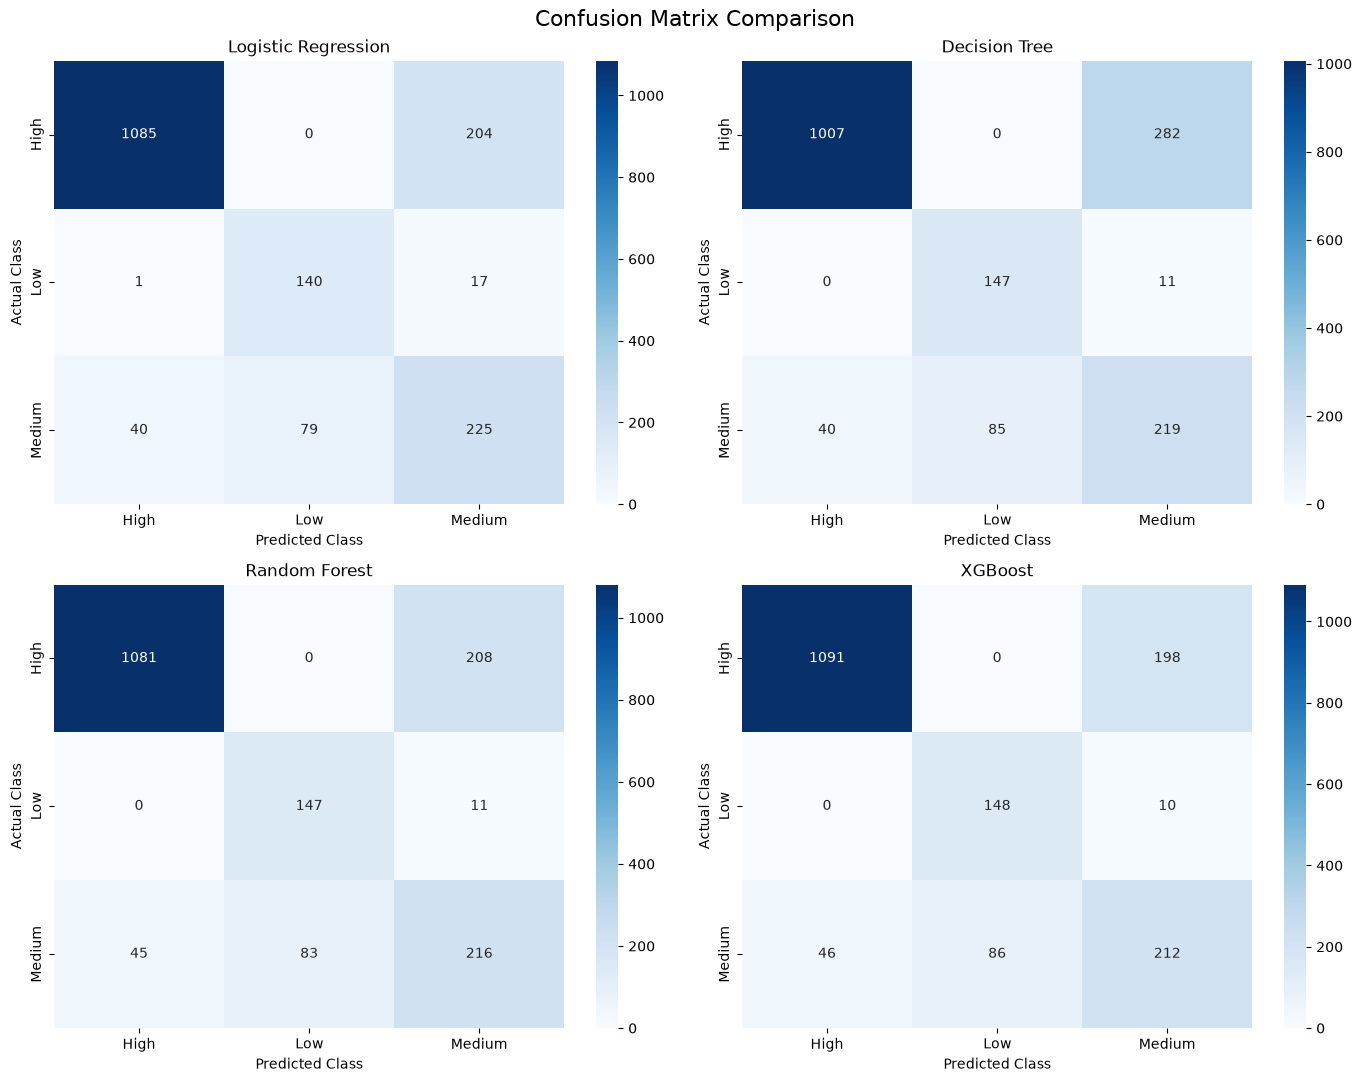

In [67]:
# confusion matrix for all models

# Create subplot for four models

fig, axes = plt.subplots(
    2, 2,
    figsize=(14, 11)
)

axes = axes.flatten()

# Generate confusion matrix

for index, (model_name, predictions) in enumerate(
    model_predictions.items()
):

    cm = confusion_matrix(
        y_test_encoded,
        predictions,
        labels=np.arange(len(label_encoder.classes_))
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues',
        xticklabels=label_encoder.classes_,
        yticklabels=label_encoder.classes_,
        ax=axes[index]
    )

    axes[index].set_title(model_name)

    axes[index].set_xlabel("Predicted Class")

    axes[index].set_ylabel("Actual Class")

plt.suptitle(
    "Confusion Matrix Comparison",
    fontsize=16
)

plt.tight_layout()

plt.show()

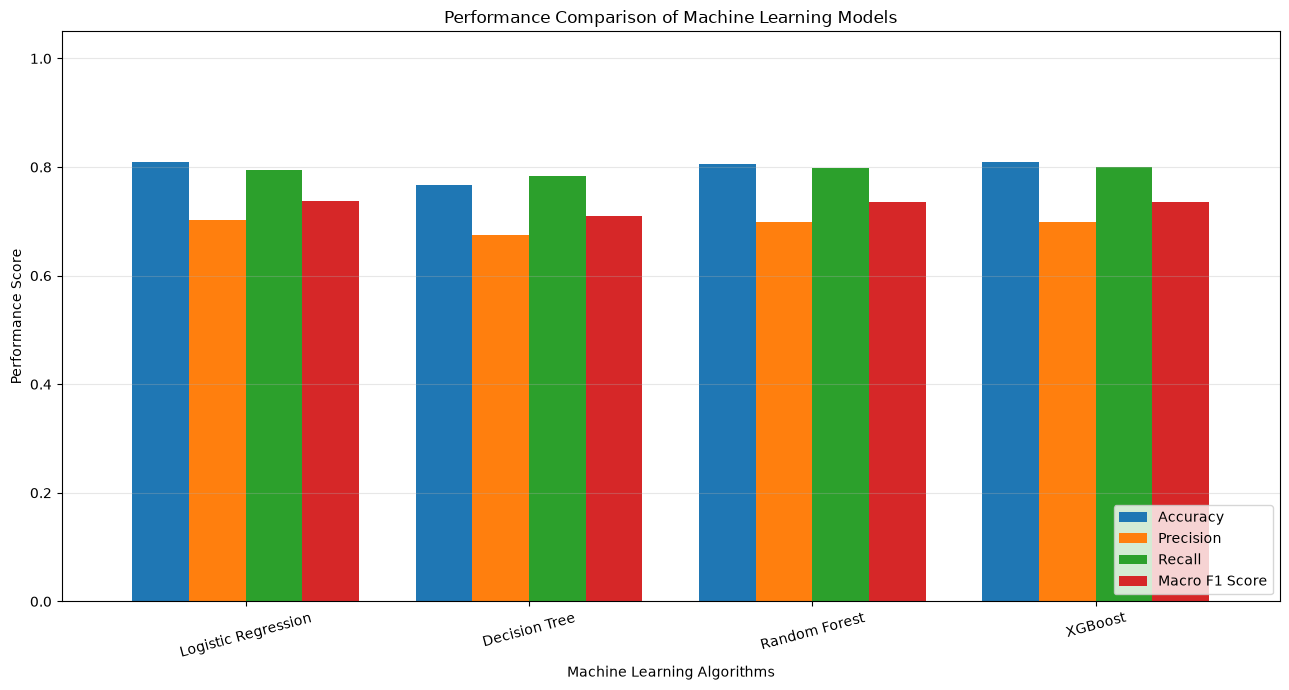

In [68]:
# compare model performance graphically
# Select metrics for comparison

metrics = [
    'Accuracy',
    'Precision',
    'Recall',
    'Macro F1 Score'
]

# Convert results into suitable format

comparison_data = evaluation_df[metrics]

# Plot comparison

comparison_data.plot(
    kind='bar',
    figsize=(13, 7),
    width=0.8
)

plt.title(
    'Performance Comparison of Machine Learning Models'
)

plt.xlabel("Machine Learning Algorithms")

plt.ylabel("Performance Score")

plt.ylim(0, 1.05)

plt.xticks(rotation=15)

plt.legend(loc='lower right')

plt.grid(axis='y', alpha=0.3)

plt.tight_layout()

plt.show()

In [69]:
#final result and best model selection

# Find best model

best_model_name = evaluation_df[
    'Macro F1 Score'
].idxmax()

best_model_score = evaluation_df.loc[
    best_model_name,
    'Macro F1 Score'
]

print("BEST MACHINE LEARNING MODEL")
print("----------------------------")

print("Model Name:", best_model_name)

print("Macro F1 Score:", round(best_model_score, 4))

print(
    "Accuracy:",
    round(evaluation_df.loc[best_model_name, 'Accuracy'], 4)
)

print("\nModel selection completed!")

BEST MACHINE LEARNING MODEL
----------------------------
Model Name: Logistic Regression
Macro F1 Score: 0.737
Accuracy: 0.8096

Model selection completed!


In [70]:
# traffic congestion hotspot identification


# Create a copy for hotspot analysis

hotspot_data = traffic_congestion.copy()

# Check required columns

required_columns = [
    'Area Name',
    'Road/Intersection Name',
    'Congestion Level',
    'Congestion_Class'
]

print("Checking required columns:")

for column in required_columns:
    print(column, ":", column in hotspot_data.columns)

# Display first five records

display(hotspot_data[required_columns].head())

Checking required columns:
Area Name : True
Road/Intersection Name : True
Congestion Level : True
Congestion_Class : True


,Area Name,Road/Intersection Name,Congestion Level,Congestion_Class
0,Indiranagar,100 Feet Road,100.000000,High
1,Indiranagar,CMH Road,100.000000,High
2,Whitefield,Marathahalli Bridge,28.347994,Low
3,Koramangala,Sony World Junction,100.000000,High
4,Koramangala,Sarjapur Road,100.000000,High


In [71]:
# Calculate area-wise congestion statistics

area_hotspots = (
    hotspot_data.groupby('Area Name')
    .agg(
        Average_Congestion=('Congestion Level', 'mean'),
        Maximum_Congestion=('Congestion Level', 'max'),
        Total_Records=('Congestion Level', 'count'),
        High_Congestion_Count=(
            'Congestion_Class',
            lambda x: (x.astype(str) == 'High').sum()
        )
    )
)

# Calculate high congestion percentage

area_hotspots['High_Congestion_Percentage'] = (
    area_hotspots['High_Congestion_Count']
    / area_hotspots['Total_Records']
) * 100

# Sort areas by average congestion

area_hotspots = area_hotspots.sort_values(
    by='Average_Congestion',
    ascending=False
)

print("AREA-WISE HOTSPOT ANALYSIS")

display(area_hotspots.round(2))

AREA-WISE HOTSPOT ANALYSIS


,Average_Congestion,Maximum_Congestion,Total_Records,High_Congestion_Count,High_Congestion_Percentage
Area Name,,,,,
Koramangala,93.99,100.0,1364,1221,89.52
M.G. Road,90.58,100.0,1501,1346,89.67
Indiranagar,87.64,100.0,1720,1480,86.05
Hebbal,80.09,100.0,950,650,68.42
Jayanagar,77.00,100.0,1173,744,63.43
Whitefield,69.05,100.0,942,481,51.06
Yeshwanthpur,62.37,100.0,734,293,39.92
Electronic City,54.45,100.0,552,124,22.46


In [72]:
# Calculate road-wise congestion

road_hotspots = (
    hotspot_data.groupby('Road/Intersection Name')
    .agg(
        Average_Congestion=('Congestion Level', 'mean'),
        Maximum_Congestion=('Congestion Level', 'max'),
        Total_Records=('Congestion Level', 'count'),
        High_Congestion_Count=(
            'Congestion_Class',
            lambda x: (x.astype(str) == 'High').sum()
        )
    )
)

# Calculate high congestion percentage

road_hotspots['High_Congestion_Percentage'] = (
    road_hotspots['High_Congestion_Count']
    / road_hotspots['Total_Records']
) * 100

# Sort by average congestion

road_hotspots = road_hotspots.sort_values(
    by='Average_Congestion',
    ascending=False
)

# Select top 10 roads

top_10_roads = road_hotspots.head(10)

print("TOP 10 TRAFFIC CONGESTION HOTSPOTS")

display(top_10_roads.round(2))

TOP 10 TRAFFIC CONGESTION HOTSPOTS


,Average_Congestion,Maximum_Congestion,Total_Records,High_Congestion_Count,High_Congestion_Percentage
Road/Intersection Name,,,,,
Sony World Junction,94.13,100.0,684,614,89.77
Sarjapur Road,93.85,100.0,680,607,89.26
Anil Kumble Circle,90.78,100.0,759,685,90.25
Trinity Circle,90.37,100.0,742,661,89.08
CMH Road,88.18,100.0,860,745,86.63
100 Feet Road,87.11,100.0,860,735,85.47
Hebbal Flyover,80.66,100.0,474,329,69.41
Ballari Road,79.51,100.0,476,321,67.44
South End Circle,77.28,100.0,593,377,63.58


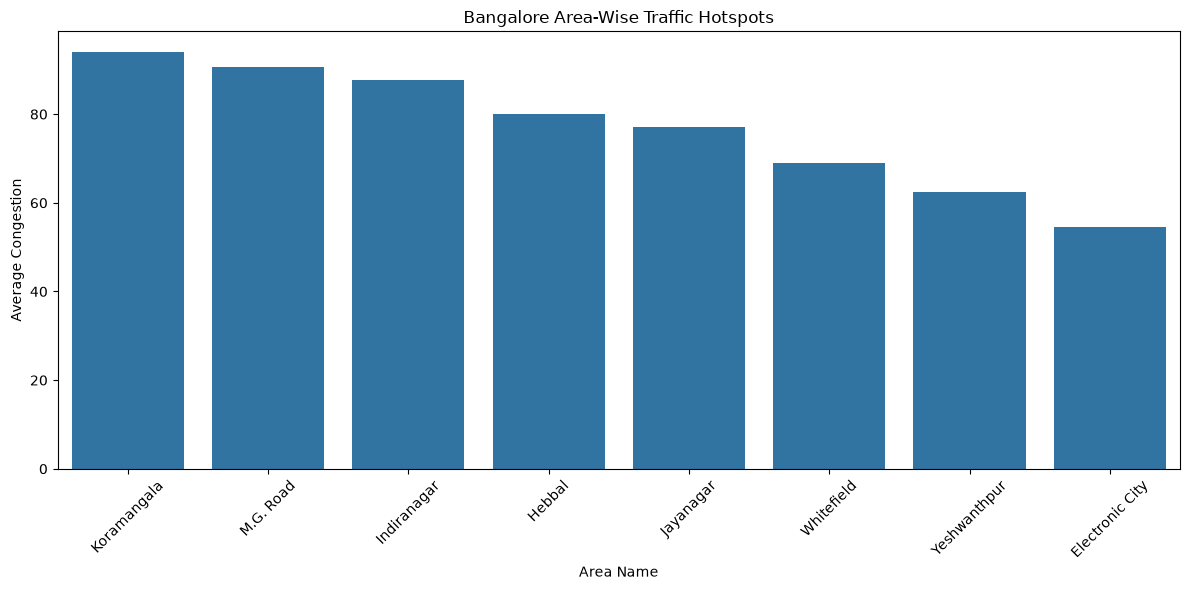

In [73]:
# Plot area-wise congestion

plt.figure(figsize=(12, 6))

sns.barplot(
    x=area_hotspots.index,
    y=area_hotspots['Average_Congestion']
)

plt.title('Bangalore Area-Wise Traffic Hotspots')

plt.xlabel('Area Name')

plt.ylabel('Average Congestion')

plt.xticks(rotation=45)

plt.tight_layout()

import os

os.makedirs('results/graphs', exist_ok=True)

plt.savefig(
    'results/graphs/area_wise_hotspots.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

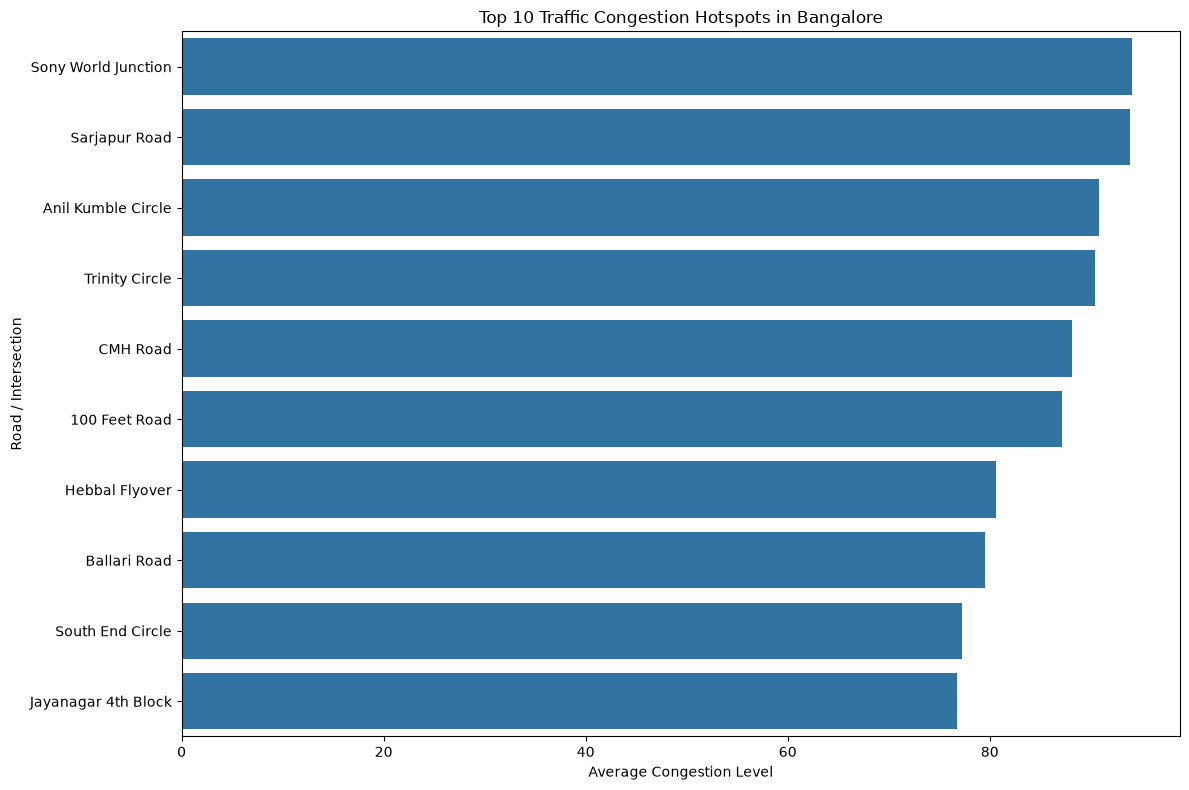

In [74]:
# visualize top 10 congested Roads

# Plot top 10 congested roads

plt.figure(figsize=(12, 8))

sns.barplot(
    x=top_10_roads['Average_Congestion'],
    y=top_10_roads.index
)

plt.title('Top 10 Traffic Congestion Hotspots in Bangalore')

plt.xlabel('Average Congestion Level')

plt.ylabel('Road / Intersection')

plt.tight_layout()

plt.savefig(
    'results/graphs/top_10_road_hotspots.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

In [75]:
#save hotspot analysis results

# Create results directory

os.makedirs('results/hotspots', exist_ok=True)

# Save area-wise hotspot results

area_hotspots.to_csv(
    'results/hotspots/area_hotspots.csv'
)

# Save road-wise hotspot results

road_hotspots.to_csv(
    'results/hotspots/road_hotspots.csv'
)

# Save top 10 roads

top_10_roads.to_csv(
    'results/hotspots/top_10_hotspots.csv'
)

print("Hotspot analysis saved successfully!")

print("\nFiles created:")
print("1. area_hotspots.csv")
print("2. road_hotspots.csv")
print("3. top_10_hotspots.csv")

Hotspot analysis saved successfully!

Files created:
1. area_hotspots.csv
2. road_hotspots.csv
3. top_10_hotspots.csv


In [76]:
# Import required libraries

import os
import joblib
import numpy as np
import pandas as pd

print("Libraries imported successfully!")

Libraries imported successfully!


In [77]:
%pip install joblib

Note: you may need to restart the kernel to use updated packages.


In [78]:
#select the best model
# Select best model

best_model = models[best_model_name]

# Display model details

print("BEST MODEL SELECTED")
print("--------------------")

print("Model Name:", best_model_name)

print("Accuracy:",
      round(evaluation_df.loc[best_model_name, 'Accuracy'], 4))

print("Macro F1 Score:",
      round(evaluation_df.loc[best_model_name, 'Macro F1 Score'], 4))

print("\nModel selected successfully!")

BEST MODEL SELECTED
--------------------
Model Name: Logistic Regression
Accuracy: 0.8096
Macro F1 Score: 0.737

Model selected successfully!


In [79]:
# create model directory
# Create model directory

os.makedirs('models', exist_ok=True)

# Check directory

print("Model directory created successfully!")

print("Directory:", os.path.abspath('models'))

Model directory created successfully!
Directory: C:\Users\Hp\models


In [80]:
# Save best machine learning model

joblib.dump(
    best_model,
    'models/best_traffic_model.pkl'
)

# Save preprocessing pipeline

joblib.dump(
    preprocessor,
    'models/traffic_preprocessor.pkl'
)

# Save label encoder

joblib.dump(
    label_encoder,
    'models/label_encoder.pkl'
)

# Save feature names

joblib.dump(
    feature_columns,
    'models/feature_columns.pkl'
)

print("All model files saved successfully!")

All model files saved successfully!


In [81]:
# Load trained model

loaded_model = joblib.load(
    'models/best_traffic_model.pkl'
)

# Load preprocessing pipeline

loaded_preprocessor = joblib.load(
    'models/traffic_preprocessor.pkl'
)

# Load label encoder

loaded_label_encoder = joblib.load(
    'models/label_encoder.pkl'
)

# Load feature columns

loaded_features = joblib.load(
    'models/feature_columns.pkl'
)

print("All saved files loaded successfully!")

print("\nLoaded Model:", type(loaded_model).__name__)

print("Number of Features:", len(loaded_features))

All saved files loaded successfully!

Loaded Model: LogisticRegression
Number of Features: 15


In [82]:
# test prediction using a new record

# Select one testing record

new_traffic_data = X_test.iloc[[0]].copy()

# Transform input using saved preprocessing pipeline

new_traffic_processed = loaded_preprocessor.transform(
    new_traffic_data
)

# Predict congestion class

prediction = loaded_model.predict(
    new_traffic_processed
)

# Convert numerical prediction into original category

predicted_congestion = loaded_label_encoder.inverse_transform(
    prediction
)

# Display result

print("TRAFFIC CONGESTION PREDICTION")
print("=" * 40)

print("\nInput Traffic Data:")

display(new_traffic_data)

print("\nPredicted Congestion Level:")

print(predicted_congestion[0])

TRAFFIC CONGESTION PREDICTION

Input Traffic Data:


,Year,Month,Day,Day_of_Week,Is_Weekend,Incident Reports,Traffic Signal Compliance,Public Transport Usage,Parking Usage,Pedestrian and Cyclist Count,Area Name,Road/Intersection Name,Weather Conditions,Roadwork and Construction Activity,Season
7145,2024,2,1,3,0,0,99.208194,35.918108,98.318508,104,Indiranagar,100 Feet Road,Overcast,No,Winter



Predicted Congestion Level:
High


In [83]:
# final verification 

# Verify saved model files

model_files = [
    'models/best_traffic_model.pkl',
    'models/traffic_preprocessor.pkl',
    'models/label_encoder.pkl',
    'models/feature_columns.pkl'
]

print("MODEL FILE VERIFICATION")
print("=" * 40)

for file in model_files:

    if os.path.exists(file):

        print(file, " - Saved Successfully")

    else:

        print(file, " - File Not Found")

print("\nStep 11 completed!")

MODEL FILE VERIFICATION
models/best_traffic_model.pkl  - Saved Successfully
models/traffic_preprocessor.pkl  - Saved Successfully
models/label_encoder.pkl  - Saved Successfully
models/feature_columns.pkl  - Saved Successfully

Step 11 completed!


In [84]:
#streamlit

%pip install streamlit

Note: you may need to restart the kernel to use updated packages.


In [85]:
import streamlit as st
import sklearn
import joblib
import pandas as pd
import numpy as np

print("Streamlit version:", st.__version__)

print("Scikit-learn version:", sklearn.__version__)

print("All application libraries are ready!")

Streamlit version: 1.58.0
Scikit-learn version: 1.9.0
All application libraries are ready!


In [86]:
%%writefile app.py

import streamlit as st
import pandas as pd
import numpy as np
import joblib
import os

from datetime import date

# --------------------------------
# PAGE CONFIGURATION
# --------------------------------

st.set_page_config(
    page_title="Bangalore Traffic Prediction",
    page_icon="🚦",
    layout="wide"
)

# --------------------------------
# LOAD TRAINED MODEL
# --------------------------------

@st.cache_resource
def load_model():

    model = joblib.load(
        "models/best_traffic_model.pkl"
    )

    preprocessor = joblib.load(
        "models/traffic_preprocessor.pkl"
    )

    label_encoder = joblib.load(
        "models/label_encoder.pkl"
    )

    features = joblib.load(
        "models/feature_columns.pkl"
    )

    return model, preprocessor, label_encoder, features


# --------------------------------
# LOAD DATASET
# --------------------------------

@st.cache_data
def load_dataset():

    return pd.read_csv(
        "Banglore_traffic_Dataset.csv"
    )


model, preprocessor, label_encoder, features = load_model()

data = load_dataset()


# --------------------------------
# APPLICATION HEADER
# --------------------------------

st.title("🚦 Bangalore Traffic Congestion Prediction")

st.write(
    "Machine Learning Based Traffic Congestion "
    "Classification and Hotspot Analysis"
)

st.divider()

st.subheader("Enter Traffic Information")


# --------------------------------
# USER INPUT FORM
# --------------------------------

with st.form("traffic_prediction_form"):

    col1, col2 = st.columns(2)

    # Area selection

    with col1:

        area = st.selectbox(
            "Select Area",
            sorted(data["Area Name"].dropna().unique())
        )

        road = st.selectbox(
            "Select Road / Intersection",
            sorted(
                data["Road/Intersection Name"]
                .dropna()
                .unique()
            )
        )

        weather = st.selectbox(
            "Weather Conditions",
            sorted(
                data["Weather Conditions"]
                .dropna()
                .unique()
            )
        )

    with col2:

        roadwork = st.selectbox(
            "Roadwork Activity",
            sorted(
                data["Roadwork and Construction Activity"]
                .dropna()
                .unique()
            )
        )

        selected_date = st.date_input(
            "Select Observation Date",
            value=date(2024, 8, 1)
        )

    st.divider()

    st.subheader("Additional Traffic Information")

    numeric_features = [
        "Incident Reports",
        "Traffic Signal Compliance",
        "Public Transport Usage",
        "Parking Usage",
        "Pedestrian and Cyclist Count"
    ]

    numeric_values = {}

    col3, col4 = st.columns(2)

    for index, feature in enumerate(numeric_features):

        column = col3 if index % 2 == 0 else col4

        with column:

            median_value = float(
                pd.to_numeric(data[feature], errors="coerce").median()
            )

            numeric_values[feature] = st.number_input(
                feature,
                value=median_value
            )

    # Submit button

    submit = st.form_submit_button(
        "Predict Traffic Congestion",
        use_container_width=True
    )


# --------------------------------
# PREDICTION
# --------------------------------

if submit:

    # Extract date features

    year = selected_date.year

    month = selected_date.month

    day = selected_date.day

    day_of_week = selected_date.weekday()

    is_weekend = int(day_of_week >= 5)

    # Season function

    if month in [12, 1, 2]:

        season = "Winter"

    elif month in [3, 4, 5]:

        season = "Summer"

    elif month in [6, 7, 8, 9]:

        season = "Monsoon"

    else:

        season = "Post-Monsoon"

    # Create input dictionary

    input_data = {

        "Year": year,

        "Month": month,

        "Day": day,

        "Day_of_Week": day_of_week,

        "Is_Weekend": is_weekend,

        "Incident Reports": numeric_values["Incident Reports"],

        "Traffic Signal Compliance": numeric_values["Traffic Signal Compliance"],

        "Public Transport Usage": numeric_values["Public Transport Usage"],

        "Parking Usage": numeric_values["Parking Usage"],

        "Pedestrian and Cyclist Count": numeric_values["Pedestrian and Cyclist Count"],

        "Area Name": area,

        "Road/Intersection Name": road,

        "Weather Conditions": weather,

        "Roadwork and Construction Activity": roadwork,

        "Season": season

    }

    # Convert dictionary into DataFrame

    input_df = pd.DataFrame(
        [input_data]
    )

    # Arrange columns in training order

    input_df = input_df[features]

    # Preprocess input

    processed_data = preprocessor.transform(
        input_df
    )

    # Predict congestion

    prediction = model.predict(
        processed_data
    )

    # Convert numerical prediction into text

    result = label_encoder.inverse_transform(
        prediction
    )[0]

    # Display prediction

    st.divider()

    st.subheader("Prediction Result")

    if result == "High":

        st.error("HIGH TRAFFIC CONGESTION")

    elif result == "Medium":

        st.warning("MEDIUM TRAFFIC CONGESTION")

    else:

        st.success("LOW TRAFFIC CONGESTION")

    st.write("Predicted Category:", result)

    # Show submitted input

    with st.expander("View Submitted Traffic Information"):

        st.dataframe(
            input_df,
            use_container_width=True
        )

    st.caption(
        "This application classifies congestion from supplied "
        "traffic conditions. It does not forecast future traffic."
    )

Writing app.py


In [87]:
import os

required_files = [
    "app.py",
    "Banglore_traffic_Dataset.csv",
    "models/best_traffic_model.pkl",
    "models/traffic_preprocessor.pkl",
    "models/label_encoder.pkl",
    "models/feature_columns.pkl"
]

print("APPLICATION FILE VERIFICATION")
print("=" * 45)

for file in required_files:

    if os.path.exists(file):
        print(file, " - Available")
    else:
        print(file, " - Missing")

APPLICATION FILE VERIFICATION
app.py  - Available
Banglore_traffic_Dataset.csv  - Available
models/best_traffic_model.pkl  - Available
models/traffic_preprocessor.pkl  - Available
models/label_encoder.pkl  - Available
models/feature_columns.pkl  - Available


In [91]:
import subprocess
import sys

result = subprocess.run(
    [sys.executable, "-m", "streamlit", "--version"],
    capture_output=True,
    text=True
)

print(result.stdout)

if result.returncode == 0:
    print("Streamlit is ready!")
else:
    print("Install Streamlit using: %pip install streamlit")

Streamlit, version 1.58.0

Streamlit is ready!


In [92]:
import os

# Get current working directory

project_path = os.getcwd()

print("Your Project Location:")
print(project_path)

# Check app.py

print("\nApp.py Exists:", os.path.exists("app.py"))

# Display files

print("\nFiles in Current Folder:")

print(os.listdir())

Your Project Location:
C:\Users\Hp

App.py Exists: True

Files in Current Folder:
['-1.14-windows.xml', '.anaconda', '.conda', '.continuum', '.copilot', '.dotnet', '.ipynb_checkpoints', '.ipython', '.jdks', '.jupyter', '.VirtualBox', '.vscode', '.vscode-shared', 'a.out', 'anaconda3', 'anaconda_projects', 'app.py', 'AppData', 'Application Data', 'Banglore_traffic_Dataset.csv', 'basic cleaning .ipynb', 'c language', 'Contacts', 'Cookies', 'Desktop', 'Documents', 'Downloads', 'Favorites', 'first.cpp', 'hello.c', 'IdeaProjects', 'Links', 'Local Settings', 'miniconda3', 'models', 'Music', 'My Documents', 'NetHood', 'new', 'newcode.cpp', 'newone.py', 'NTUSER.DAT', 'ntuser.dat.LOG1', 'ntuser.dat.LOG2', 'NTUSER.DAT{b98ee074-38d8-11f0-968f-dafb0f75c7ab}.TM.blf', 'NTUSER.DAT{b98ee074-38d8-11f0-968f-dafb0f75c7ab}.TM.blf.cnpf', 'NTUSER.DAT{b98ee074-38d8-11f0-968f-dafb0f75c7ab}.TMContainer00000000000000000001.regtrans-ms', 'NTUSER.DAT{b98ee074-38d8-11f0-968f-dafb0f75c7ab}.TMContainer000000000000000

In [94]:
import os

# Get current folder location

project_path = os.getcwd()

print("YOUR CURRENT PROJECT LOCATION:")
print(project_path)

# Display all files and folders

print("\nFILES AND FOLDERS:")

for item in os.listdir(project_path):
    print(item)

YOUR CURRENT PROJECT LOCATION:
C:\Users\Hp

FILES AND FOLDERS:
-1.14-windows.xml
.anaconda
.conda
.continuum
.copilot
.dotnet
.ipynb_checkpoints
.ipython
.jdks
.jupyter
.VirtualBox
.vscode
.vscode-shared
a.out
anaconda3
anaconda_projects
app.py
AppData
Application Data
Banglore_traffic_Dataset.csv
basic cleaning .ipynb
c language
Contacts
Cookies
Desktop
Documents
Downloads
Favorites
first.cpp
hello.c
IdeaProjects
Links
Local Settings
miniconda3
models
Music
My Documents
NetHood
new
newcode.cpp
newone.py
NTUSER.DAT
ntuser.dat.LOG1
ntuser.dat.LOG2
NTUSER.DAT{b98ee074-38d8-11f0-968f-dafb0f75c7ab}.TM.blf
NTUSER.DAT{b98ee074-38d8-11f0-968f-dafb0f75c7ab}.TM.blf.cnpf
NTUSER.DAT{b98ee074-38d8-11f0-968f-dafb0f75c7ab}.TMContainer00000000000000000001.regtrans-ms
NTUSER.DAT{b98ee074-38d8-11f0-968f-dafb0f75c7ab}.TMContainer00000000000000000001.regtrans-ms.cnpf
NTUSER.DAT{b98ee074-38d8-11f0-968f-dafb0f75c7ab}.TMContainer00000000000000000002.regtrans-ms
NTUSER.DAT{b98ee074-38d8-11f0-968f-dafb0f75c7a

In [97]:
os.startfile(project_path)

In [98]:
import os

print("Current location:", os.getcwd())

print("\nAvailable folders:")

for item in os.listdir():
    if os.path.isdir(item):
        print(item)

Current location: C:\Users\Hp

Available folders:
.anaconda
.conda
.continuum
.copilot
.dotnet
.ipynb_checkpoints
.ipython
.jdks
.jupyter
.VirtualBox
.vscode
.vscode-shared
anaconda3
anaconda_projects
AppData
Application Data
c language
Contacts
Cookies
Desktop
Documents
Downloads
Favorites
IdeaProjects
Links
Local Settings
miniconda3
models
Music
My Documents
NetHood
OneDrive
output
PrintHood
Recent
results
Saved Games
Searches
SendTo
Start Menu
Templates
Videos
VirtualBox VMs
WPS Cloud Files


In [99]:
import os

print("FILES IN C:\\Users\\Hp")
print("=" * 40)

for item in os.listdir(r"C:\Users\Hp"):

    if os.path.isfile(item):
        print("FILE:", item)

    else:
        print("FOLDER:", item)

FILES IN C:\Users\Hp
FILE: -1.14-windows.xml
FOLDER: .anaconda
FOLDER: .conda
FOLDER: .continuum
FOLDER: .copilot
FOLDER: .dotnet
FOLDER: .ipynb_checkpoints
FOLDER: .ipython
FOLDER: .jdks
FOLDER: .jupyter
FOLDER: .VirtualBox
FOLDER: .vscode
FOLDER: .vscode-shared
FILE: a.out
FOLDER: anaconda3
FOLDER: anaconda_projects
FILE: app.py
FOLDER: AppData
FOLDER: Application Data
FILE: Banglore_traffic_Dataset.csv
FILE: basic cleaning .ipynb
FOLDER: c language
FOLDER: Contacts
FOLDER: Cookies
FOLDER: Desktop
FOLDER: Documents
FOLDER: Downloads
FOLDER: Favorites
FILE: first.cpp
FILE: hello.c
FOLDER: IdeaProjects
FOLDER: Links
FOLDER: Local Settings
FOLDER: miniconda3
FOLDER: models
FOLDER: Music
FOLDER: My Documents
FOLDER: NetHood
FILE: new
FILE: newcode.cpp
FILE: newone.py
FILE: NTUSER.DAT
FILE: ntuser.dat.LOG1
FILE: ntuser.dat.LOG2
FILE: NTUSER.DAT{b98ee074-38d8-11f0-968f-dafb0f75c7ab}.TM.blf
FILE: NTUSER.DAT{b98ee074-38d8-11f0-968f-dafb0f75c7ab}.TM.blf.cnpf
FILE: NTUSER.DAT{b98ee074-38d8-11f

In [100]:
import os

required_files = [
    "app.py",
    "Banglore_traffic_Dataset.csv",
    "Traffic_Congestion.ipynb"
]

for file in required_files:

    print(
        file,
        "FOUND" if os.path.exists(file) else "NOT FOUND"
    )

app.py FOUND
Banglore_traffic_Dataset.csv FOUND
Traffic_Congestion.ipynb FOUND
